In [23]:
# importing the required libraries
import numpy as np 
import matplotlib.pyplot as plt

### DOMAIN CONSTRUCTION 

In [24]:
N= int(input("Enter the number of cells: "))
L= float(input("Enter the length of tube: "))
Li=0
dx=(L-Li)/N
x=np.linspace(Li+dx/2, L-dx/2, N)
gamma=1.4

### MAKING VARIABLES

In [25]:
U=np.zeros((3, N))
# Sod shock Conditions
rho=np.where(x<(L/2), 1.0, 0.125)
u=np.where(x<(L/2), 0, 0)
p=np.where(x<(L/2), 1.0, 0.1)
# Energy equation 
E= (p/(gamma-1))+((rho*(u**2))*0.5)

U[0]=rho
U[1]= rho*u
U[2]=E

# function for variable recovering 
def Intial(U):
    rho=U[0]
    u=U[1]/rho
    p= (gamma-1)*(U[2]-(0.5*rho*(u**2)))
    return rho, u, p



In [26]:
# flux function 
def flux(U):
    rho, u, p= Intial(U)
    F=np.zeros_like(U)
    F[0]= rho*u
    F[1]= (rho*(u**2))+p
    F[2]=u*(U[2]+p)
    return F

In [27]:
# HLL Scheme 
def HLL(Ul, Ur):
    rhol, ul, pl= Intial(Ul)
    rhor, ur, pr= Intial(Ur)
    Fl=flux(Ul)
    Fr=flux(Ur)
    al=np.sqrt(gamma*pl/rhol)
    ar=np.sqrt(gamma*pr/rhor)
    Sr= max(np.abs(ul)+al, np.abs(ur)+ar)
    Sl=min(np.abs(ul)-al, np.abs(ur)-ar)
    if Sl >=0:
        F=Fl
    elif Sr <= 0:
        F=Fr
    else:
        F= ((Sr*Fl)-(Sl*Fr) + ((Sl*Sr)*(Ur-Ul)))/(Sr-Sl)
        
    return F

In [28]:
# Time integration 
# COurant  number 
CFL = 0.5
t=0.0
t_end= 0.2

while t < t_end:
    rho, u, p = Intial(U)
    a = np.sqrt(gamma*p/rho)
    dt = CFL * (dx/np.max(np.abs(u)+a))
    if t + dt > t_end:
        dt = t_end - t

    F_interface = np.zeros((3, N+1))
    for i in range(1, N):
        F_interface[:, i] = HLL(U[:, i-1], U[:, i])

    U_new = U.copy()
    for i in range(1, N-1):
        U_new[:, i] = U[:, i] - (dt/dx)*(F_interface[:, i+1] - F_interface[:, i])
    U_new[:, 0] = U_new[:, 1]
    U_new[:, -1] = U_new[:, -2]

    U = U_new
    t += dt

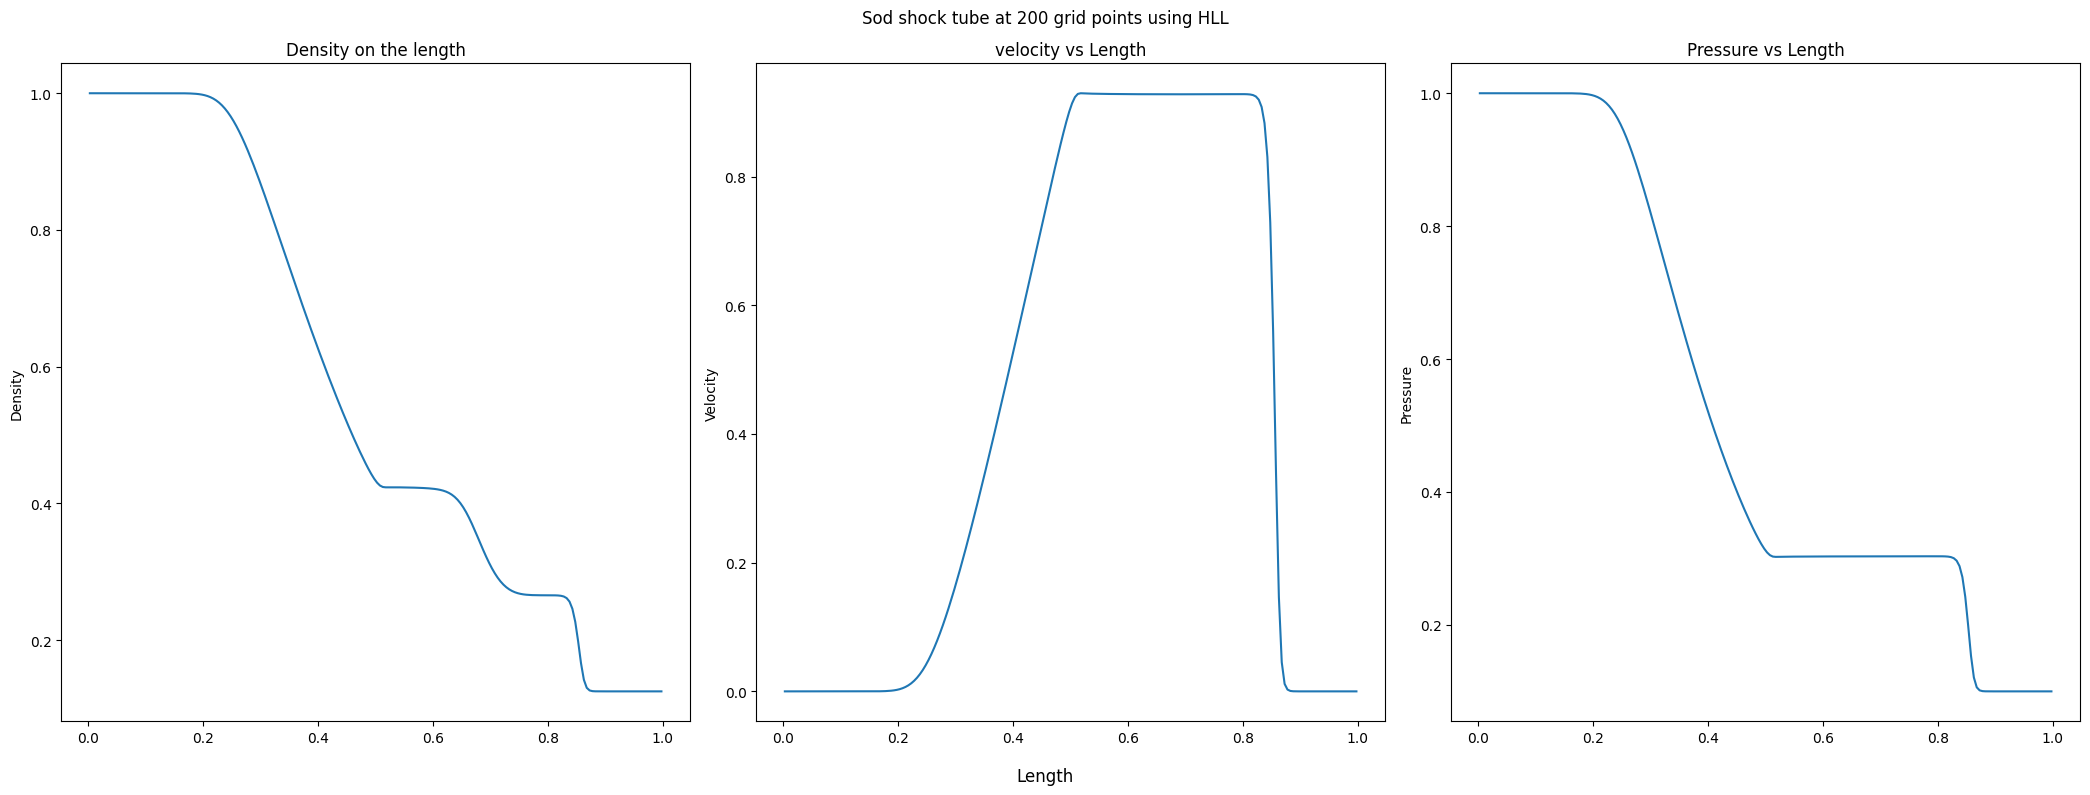

In [30]:
rho, u, p= Intial(U)
fig,ax=plt.subplots(1, 3, figsize=(21, 8), sharex=True)

ax[0].plot(x, rho)
ax[0].set_ylabel("Density")
ax[0].set_title("Density on the length")

ax[1].plot(x, u)
ax[1].set_ylabel("Velocity")
ax[1].set_title("velocity vs Length")

ax[2].plot(x, p)
ax[2].set_ylabel("Pressure")
ax[2].set_title("Pressure vs Length")
fig.supxlabel("Length")

fig.suptitle("Sod shock tube at 200 grid points using HLL")
fig.tight_layout()
plt.show()